# Canadian road-tractor casualty-collision trends

## Summary

Reproduce the first descriptive analysis from the validated collision table. The intended **2016–2025** question remains open: available event data cover **1999–2021**. The historical decade **2012–2021** and available segment **2016–2021** are reported explicitly. These are collision events, not person deaths or exposure-adjusted risks.

## Context and methods

A tractor collision contains a recorded V_TYPE=08 road tractor with or without a semitrailer. Fatal share is fatal collisions divided by fatal plus injury collisions. Heavy unit truck events (07) can overlap tractor events. No recorded tractor includes other vehicles and unknown types; it is not a car-only comparison.

### Assumptions and limits

Counts describe this public release. The selected 2014–2017 annual releases and alternate 2019 XLSX replace earlier sources after validation. The 2019 injury collision count remains two below Transport Canada's separate benchmark. The prior source files and outputs are preserved; no records were adjusted to force agreement. Strict filtering is a sensitivity analysis, not a correction. No causal model, sampling interval, person casualty total or risk-per-kilometre estimate is produced. See the dataset contract and validation findings in docs/.

In [1]:
from pathlib import Path
import hashlib, json, os, subprocess, sys, tempfile
from html import escape
import duckdb
from IPython.display import display, HTML, Image

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
output = root / "reports/trends"
env = os.environ.copy()
env["MPLCONFIGDIR"] = str(Path(tempfile.gettempdir()) / "collisions-matplotlib")
run = subprocess.run([sys.executable, "-m", "truck_collisions.analyze_trends"], cwd=root, env=env, text=True, capture_output=True, check=True)
print(run.stdout.strip())
summary = json.loads((output / "summary.json").read_text())
assert summary["analysis_code_sha256"] == hashlib.sha256((root / "src/truck_collisions/analyze_trends.py").read_bytes()).hexdigest()
assert summary["target_period_fulfilled"] is False
connection = duckdb.connect()

def quote(value):
    return "'" + str(value).replace("'", "''") + "'"

for name in ["annual_counts", "period_changes", "strict_sensitivity", "benchmark_comparison", "benchmark_period_changes", "pooled_periods"]:
    connection.execute(f"CREATE VIEW {name} AS SELECT * FROM read_csv_auto({quote(output / (name + '.csv'))})")

def show_table(sql):
    result = connection.execute(sql)
    headings = [d[0] for d in result.description]
    def fmt(value, heading):
        if value is None:
            return "—"
        if isinstance(value, float):
            return f"{value:,.2f}"
        if isinstance(value, int) and "year" not in heading:
            return f"{value:,}"
        return str(value)
    header = "".join(f"<th>{escape(h.replace('_',' '))}</th>" for h in headings)
    rows = "".join("<tr>" + "".join(f"<td>{escape(fmt(v,h))}</td>" for h,v in zip(headings,row)) + "</tr>" for row in result.fetchall())
    display(HTML(f'<div style="overflow-x:auto"><table><thead><tr>{header}</tr></thead><tbody>{rows}</tbody></table></div>'))

{
  "output_dir": "reports/trends",
  "diagnostics": {
    "events": 2949846,
    "unique_keys": 2949846,
    "first_year": 1999,
    "last_year": 2021,
    "year_count": 23,
    "unsupported_severity": 0
  },
  "tractor_events": 80540,
  "tractor_strict_events": 80529
}


## Data and independent checks

The script checks source event keys, year coverage, severity and agreement with the dataset build. This cell independently reconstructs observed tractor annual counts from the event Parquet table.

In [2]:
data = root / "data/derived/ncdb"
connection.execute(f"CREATE VIEW events AS SELECT * FROM read_parquet({quote(data / 'collisions.parquet')})")
errors = connection.execute("""
WITH direct AS (
  SELECT C_YEAR AS year,count(*) AS n,count(*) FILTER (WHERE C_SEV='1') AS fatal
  FROM events WHERE is_road_tractor GROUP BY C_YEAR
)
SELECT count(*) FROM direct d
FULL JOIN (SELECT * FROM annual_counts WHERE "group"='road_tractor' AND subset='observed') a USING(year)
WHERE d.n IS DISTINCT FROM a.casualty_collisions OR d.fatal IS DISTINCT FROM a.fatal_collisions
""").fetchone()[0]
assert errors == 0
assert connection.execute("SELECT count(*)=count(DISTINCT (C_YEAR,C_CASE)) FROM events").fetchone()[0]
print("Every observed tractor annual count matches an independent event query.")
show_table("""
SELECT year,casualty_collisions,fatal_collisions,injury_collisions,fatal_share_pct
FROM annual_counts WHERE "group"='road_tractor' AND subset='observed'
AND year IN (2012,2016,2019,2020,2021) ORDER BY year
""")

Every observed tractor annual count matches an independent event query.


year,casualty collisions,fatal collisions,injury collisions,fatal share pct
2012,"3,300",197,"3,103",5.97
2016,"3,010",193,"2,817",6.41
2019,"2,775",196,"2,579",7.06
2020,"2,122",158,"1,964",7.45
2021,"2,276",169,"2,107",7.43


## Results

### Frequency and fatal share

Fatal collisions declined more slowly than injury collisions over the historical decade. Counts and fatal shares are different measures.

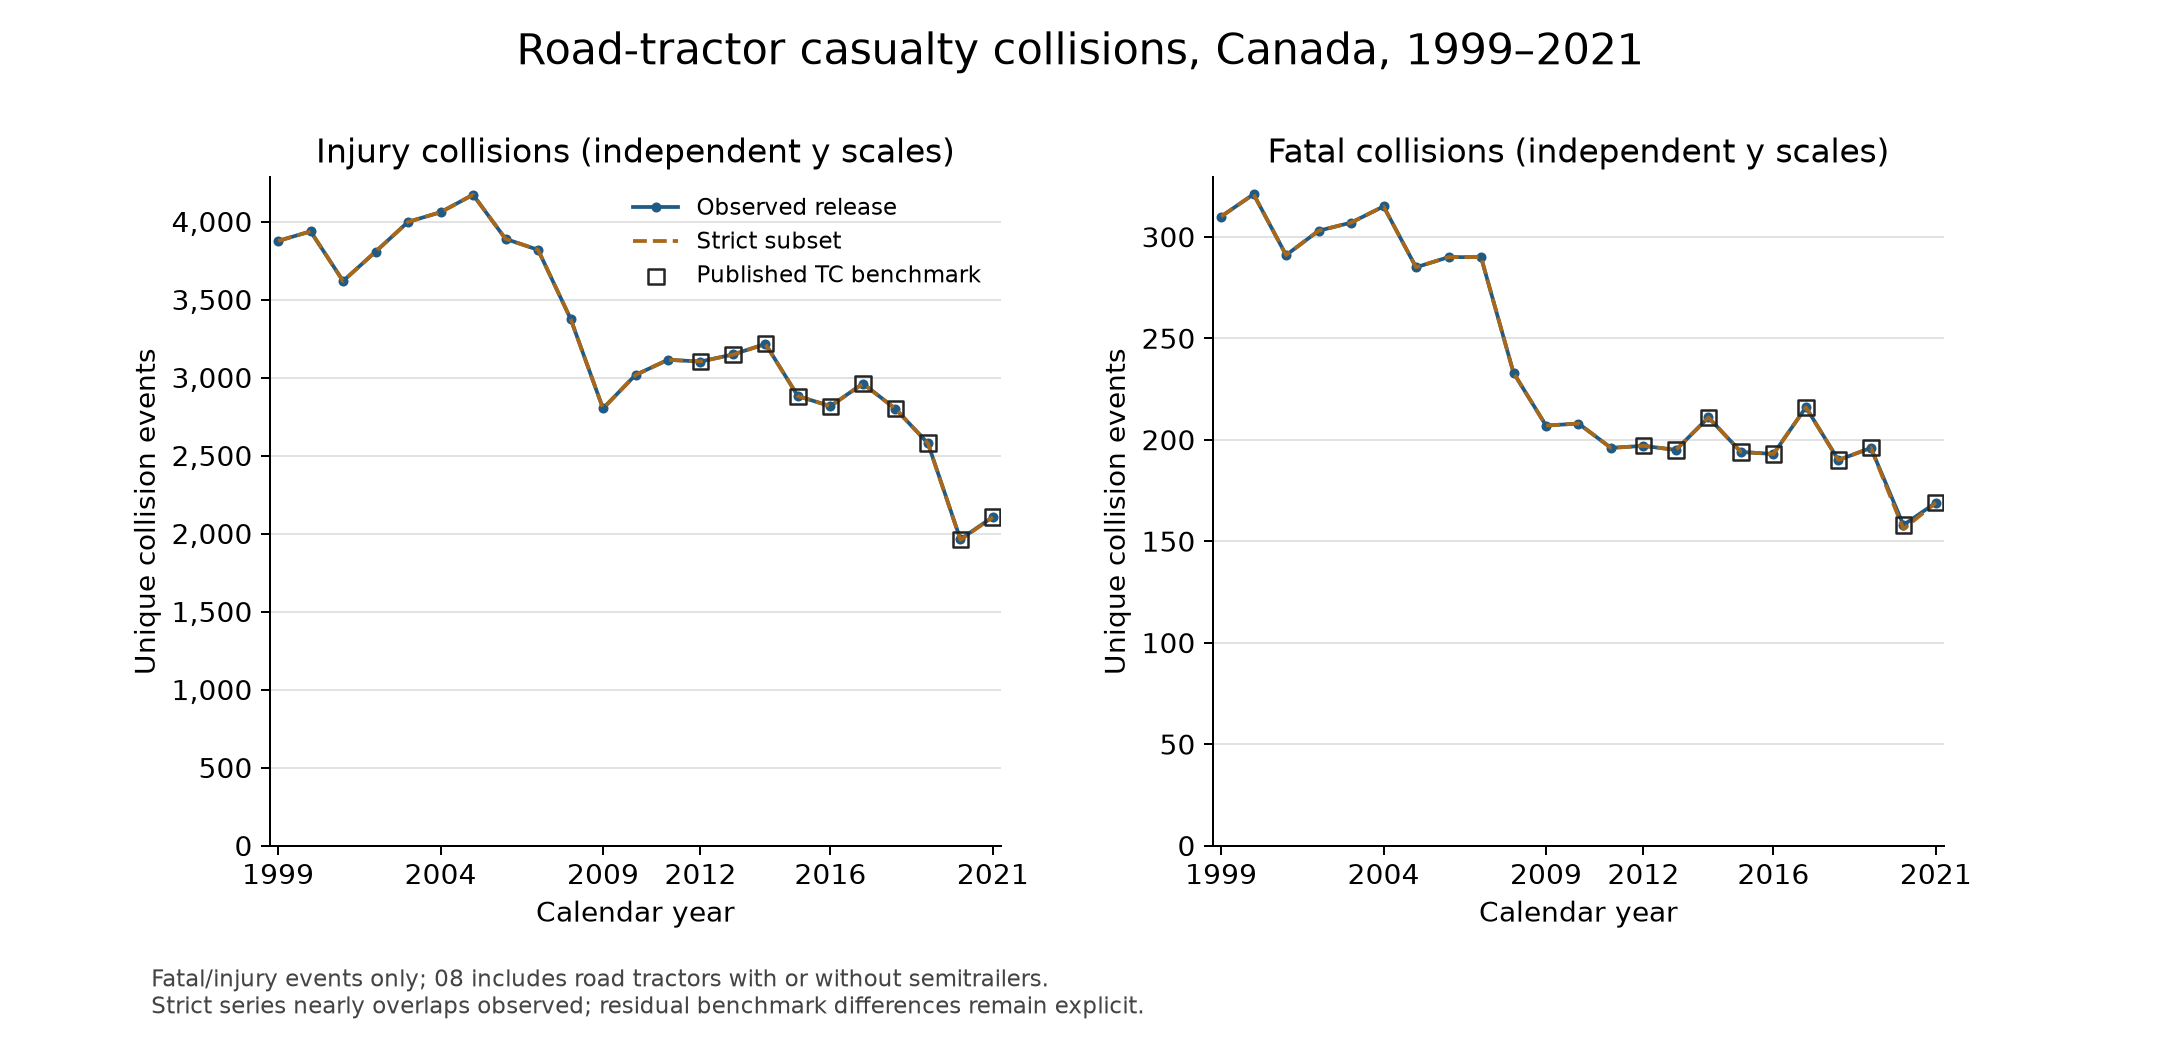

start year,end year,pct change casualty collisions,pct change fatal collisions,pct change injury collisions,change fatal share pp
2012,2019,-15.91,-0.51,-16.89,1.09
2012,2021,-31.03,-14.21,-32.10,1.46
2016,2019,-7.81,1.55,-8.45,0.65
2016,2021,-24.39,-12.44,-25.20,1.01
2019,2020,-23.53,-19.39,-23.85,0.38
2019,2021,-17.98,-13.78,-18.30,0.36
2020,2021,7.26,6.96,7.28,-0.02


In [3]:
display(Image(filename=str(output / "tractor_counts.png")))
show_table("""
SELECT start_year,end_year,pct_change_casualty_collisions,pct_change_fatal_collisions,pct_change_injury_collisions,change_fatal_share_pp
FROM period_changes WHERE "group"='road_tractor' AND subset='observed'
ORDER BY start_year,end_year
""")

### Comparison populations

Each fatal share uses that group's casualty-collision denominator. Groups overlap. Indexed counts compare relative movements without adjusting for traffic exposure.

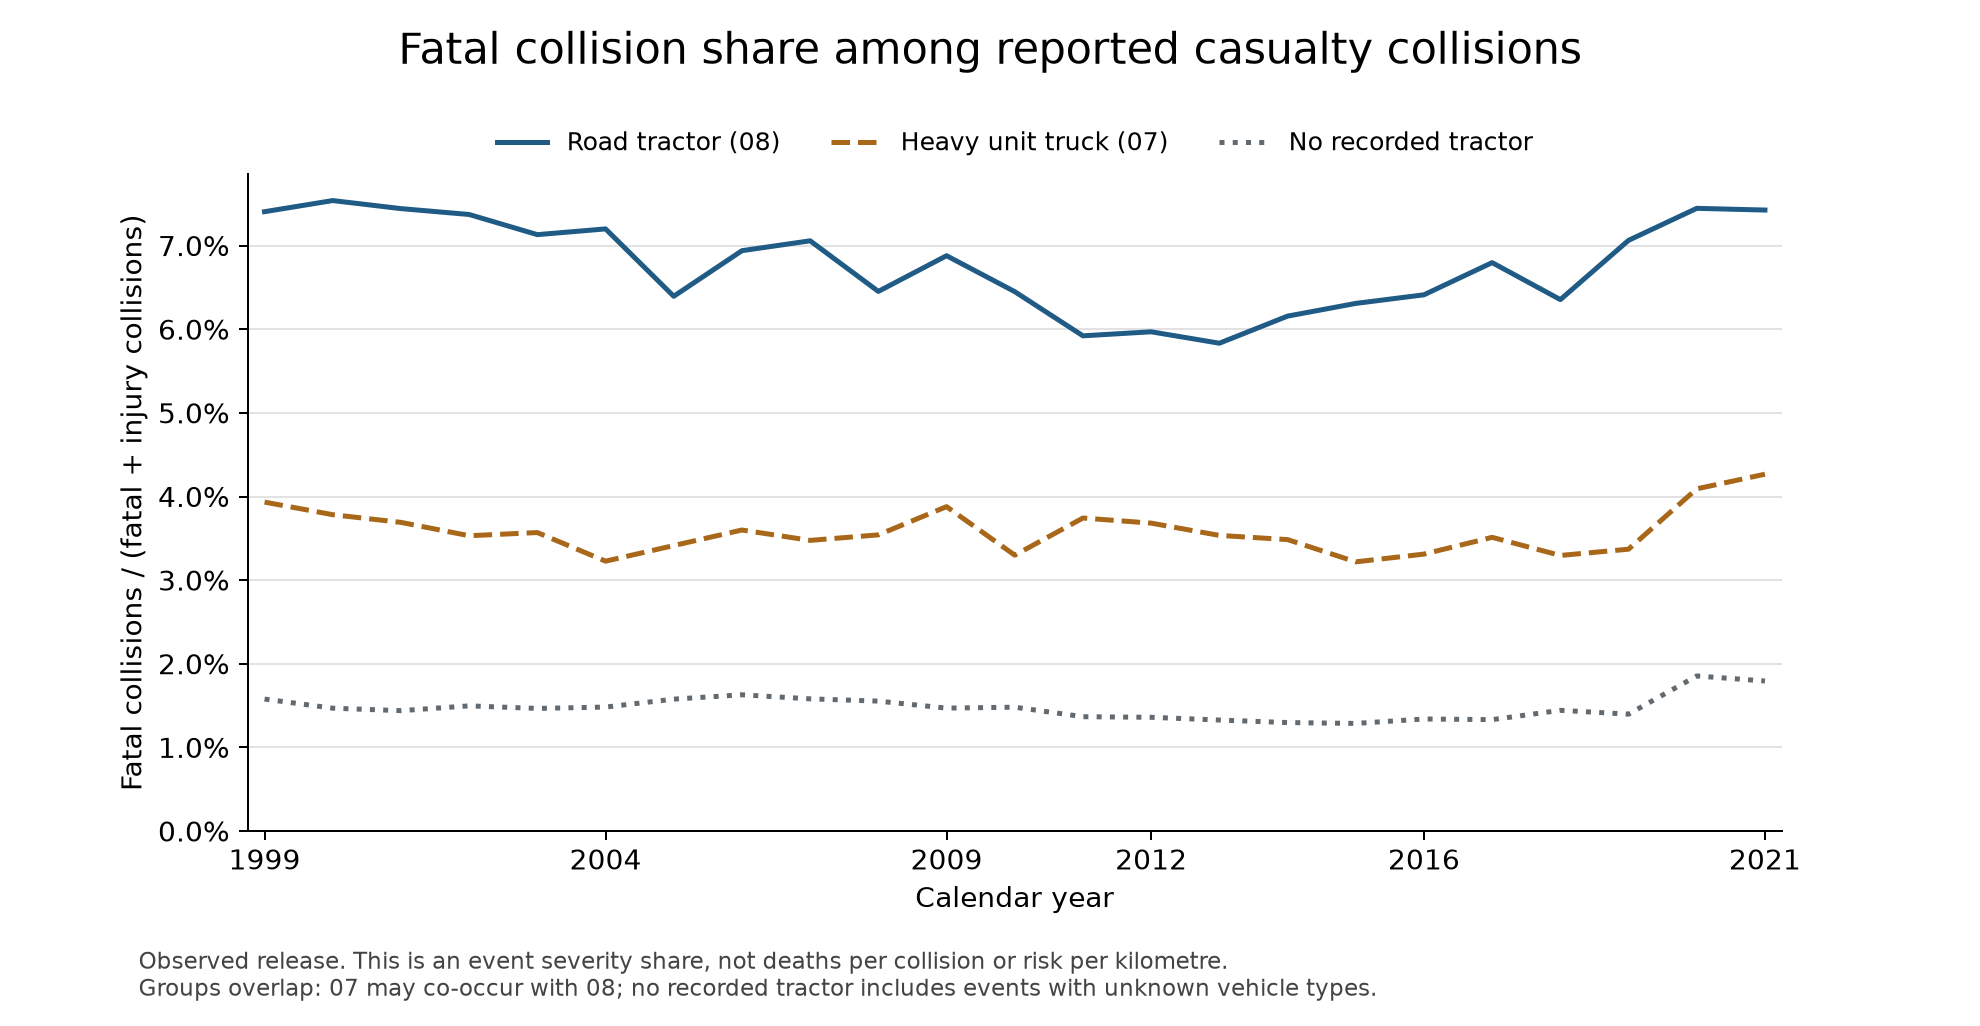

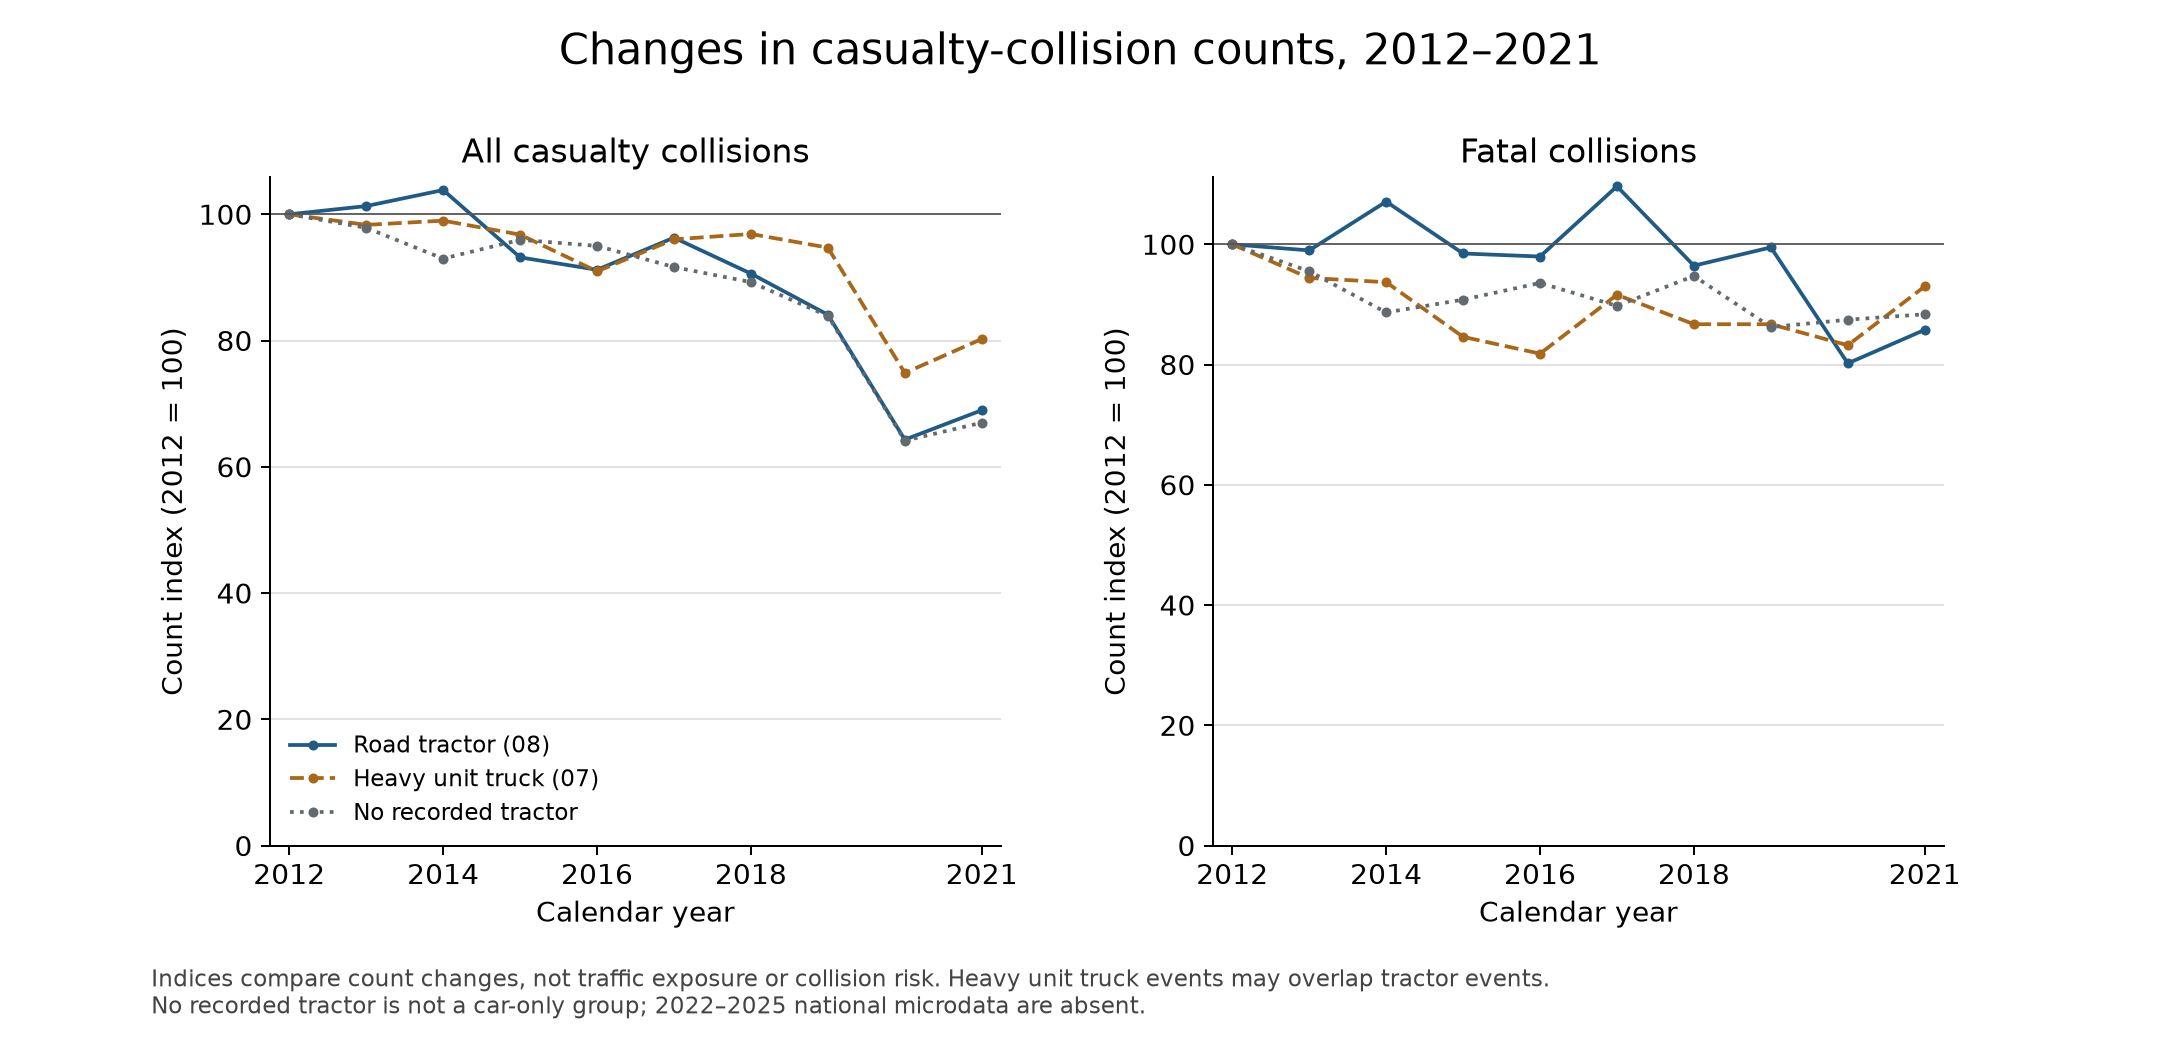

In [4]:
display(Image(filename=str(output / "fatal_share.png")))
display(Image(filename=str(output / "indexed_comparison.png")))

### Data-quality and period sensitivities

The separately published benchmark does not replace event records. Strict exclusions can disproportionately remove complex collisions. The tiny 2020–2021 share change reverses under filtering, and endpoint comparisons use the validated annual releases rather than mixing versions. The full source update includes 2014–2017 as well as 2019.

In [5]:
show_table("""
SELECT year,observed_total,published_total,observed_fatal,published_fatal,observed_fatal_share_pct,published_fatal_share_pct
FROM benchmark_comparison WHERE year IN (2016,2019,2020,2021) ORDER BY year
""")
show_table("""
SELECT year,observed_collisions,strict_collisions,excluded_collisions,observed_fatal_share_pct,strict_fatal_share_pct
FROM strict_sensitivity WHERE "group"='road_tractor' AND year>=2019 ORDER BY year
""")

year,observed total,published total,observed fatal,published fatal,observed fatal share pct,published fatal share pct
2016,"3,010","3,010",193,193,6.41,6.41
2019,"2,775","2,777",196,196,7.06,7.06
2020,"2,122","2,122",158,158,7.45,7.45
2021,"2,276","2,276",169,169,7.43,7.43


year,observed collisions,strict collisions,excluded collisions,observed fatal share pct,strict fatal share pct
2019,"2,775","2,775",0,7.06,7.06
2020,"2,122","2,116",6,7.45,7.37
2021,"2,276","2,275",1,7.43,7.43


## Takeaways

The observed historical endpoint pattern is fewer tractor casualty collisions and a larger fatal collision share, with fatal events declining more slowly than injury events. The same broad direction survives strict filtering. Fatal share also rose in the comparison populations, so this does not establish uniquely worsening tractor severity.

The 2020 fall and 2021 rebound, residual 2019 publication difference, unknown vehicle types and missing 2022–2025 data qualify interpretation. These counts do not explain causes or risk per kilometre. Person-level casualty validation is available in notebook 03. Exposure compatibility and configuration/environment comparisons are separate future phases.

Full methods, tables, figures, source hashes and sensitivities are in reports/trends/findings.md and summary.json.

In [6]:
connection.close()
print("Trend analysis notebook completed; source collision data were read without modification.")

Trend analysis notebook completed; source collision data were read without modification.
